# Chapter 27 | Worked solutions

Models for Code

All eleven exercises are solved here, from half-open intervals to repository evaluation. The programs are checked-in teaching fixtures, not model-generated samples. We can derive their answers independently and see exactly which tests reject them.

The same fixture passes 21 of 24 individual checks but only 2 of 4 complete candidate evaluations. A pool can contain a correct solution even when a selector returns an incorrect one. Keeping the denominator and selection rule visible is the main lesson of these solutions.

## Setup

Run from the companion repository or a subdirectory. The canonical examples use the Python standard library; the solution plots also use Matplotlib. No model download or execution of newly generated programs is needed.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
from fractions import Fraction
from itertools import combinations
from math import comb
import matplotlib.pyplot as plt
from IPython.display import display
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/ch27_code_models/model.py").exists())
sys.path.insert(0, str(root))
from examples.ch27_code_models.model import (
    Case, pass_at_k, score_candidate, serialize_fim, strict_overlap,
)
from examples.ch27_code_models.run_examples import (
    CANDIDATES, SMOKE, EDGES, benchmark_example,
)
plt.rcParams.update({"font.size": 11, "figure.figsize": (7, 3.6),
                     "axes.spines.top": False, "axes.spines.right": False})
print("Loaded known local functions; no generated code is executed.")

Loaded known local functions; no generated code is executed.


## 1. Check the boundaries

The right endpoint is excluded because this is the stated half-open contract. This convention lets consecutive intervals meet without sharing an integer. List the integers before comparing formulas.

| First interval and contents | Second interval and contents | Shared integers |
| --- | --- | --- |
| $[0,2)$: 0, 1 | $[1,4)$: 1, 2, 3 | 1 |
| $[1,4)$: 1, 2, 3 | $[4,7)$: 4, 5, 6 | None |
| $[2,2)$: none | $[0,5)$: 0, 1, 2, 3, 4 | None |

In the second row, 4 belongs only to the second interval. In the third, the first interval is empty even though the other one contains 2. With integer endpoints, $\max(0,\min(a_1,b_1)-\max(a_0,b_0))$ counts the common integers.

In [2]:
pairs = [((0, 2), (1, 4)), ((1, 4), (4, 7)), ((2, 2), (0, 5))]
for (a, b), expected in zip(pairs, [{1}, set(), set()]):
    shared = set(range(*a)) & set(range(*b))
    assert shared == expected
    assert strict_overlap(a, b) is bool(shared)
    print(f"{a}, {b}: shared={sorted(shared)}, overlap={bool(shared)}")

(0, 2), (1, 4): shared=[1], overlap=True
(1, 4), (4, 7): shared=[], overlap=False
(2, 2), (0, 5): shared=[], overlap=False


## 2. Reorder an edit

Choose a function that clips a negative integer to zero. The prefix is `def clip_at_zero(n):` followed by a newline and four indentation spaces. The suffix contains `assert clip_at_zero(-3) == 0` and `assert clip_at_zero(4) == 4` on separate lines. In file order, the missing body lies between the prefix and suffix.

The serialized prompt puts the prefix marker and prefix first, the suffix marker and suffix next, and the middle marker last. The decoder then generates the missing body. A suitable body is `return max(0, n)`, inserted after the prefix's indentation and before the suffix. The two assertions are visible when generation starts: the first says a negative input should become zero; the second rules out always returning zero.

The model remains causal in this serialized order. It can read the suffix because the suffix is already in its prompt. The teaching markers are illustrative; a real checkpoint needs its own special tokens and stopping convention. These two assertions constrain the body but do not prove correctness for every integer.

In [3]:
prefix = "def clip_at_zero(n):\n    "
suffix = "\nassert clip_at_zero(-3) == 0\nassert clip_at_zero(4) == 4\n"
prompt = serialize_fim(prefix, suffix)
middle = "return max(0, n)"
assembled = prefix + middle + suffix
assert prompt.endswith("<fim_middle>")
assert prompt.index("<fim_suffix>") < prompt.index("<fim_middle>")
assert "    return max(0, n)" in assembled
print("Serialized prompt:\n" + prompt)
print("Reassembled teaching example:\n" + assembled)

Serialized prompt:
<fim_prefix>def clip_at_zero(n):
    <fim_suffix>
assert clip_at_zero(-3) == 0
assert clip_at_zero(4) == 4
<fim_middle>
Reassembled teaching example:
def clip_at_zero(n):
    return max(0, n)
assert clip_at_zero(-3) == 0
assert clip_at_zero(4) == 4



## 3. Distinguish two expressions

Write $\ell=\max(a_0,b_0)$ and $r=\min(a_1,b_1)$. Compare the two expressions on these three cases.

| Intervals | $\ell$ | $r$ | $\ell\le r$ | $\ell<r$ | Expected |
| --- | --- | --- | --- | --- | --- |
| $[0,4)$ and $[2,6)$ | 2 | 4 | True | True | True |
| $[0,2)$ and $[3,5)$ | 3 | 2 | False | False | False |
| $[0,2)$ and $[2,5)$ | 2 | 2 | True | False | False |

The smoke suite already covers a clear overlap and a gap. Adding the touching case tests equality, where the two expressions disagree. The non-strict comparison accepts a zero-length intersection. The strict comparison matches the half-open contract.

In [4]:
for a, b in [((0, 4), (2, 6)), ((0, 2), (3, 5)), ((0, 2), (2, 5))]:
    left, right = max(a[0], b[0]), min(a[1], b[1])
    expected = bool(set(range(*a)) & set(range(*b)))
    assert (left < right) is expected
    print(f"left={left}, right={right}: <= {left<=right}, "
          f"< {left<right}, expected {expected}")

left=2, right=4: <= True, < True, expected True
left=3, right=2: <= False, < False, expected False
left=2, right=2: <= True, < False, expected False


## 4. Count successful pairs

For this five-candidate exercise, label the two passing candidates A and B and the failures C, D, and E. There are $\binom{5}{2}=10$ unordered pairs of distinct candidate indices. AB contains two passes. AC, AD, AE, BC, BD, and BE contain one pass. CD, CE, and DE contain none. Thus seven of ten pairs succeed, giving $\mathrm{pass@}2=7/10=0.7$.

Equivalently, subtract the three all-failing pairs: $1-\binom{3}{2}/\binom{5}{2}=0.7$. The plot groups these ten pairs by their number of passes; its vertical axis counts pairs, not candidates. These labels belong to this hypothetical five-candidate pool; the chapter's four-function fixture has B and D passing.

In [5]:
names = "ABCDE"
passing = {"A", "B"}
groups = {0: [], 1: [], 2: []}
for pair in combinations(names, 2):
    groups[len(set(pair) & passing)].append("".join(pair))
assert [len(groups[k]) for k in [0, 1, 2]] == [3, 6, 1]
assert pass_at_k(5, 2, 2) == 0.7
for count, pairs in groups.items():
    print(f"{count} passes: {', '.join(pairs)} ({len(pairs)} pairs)")
print("At least one pass: 7 / 10")

0 passes: CD, CE, DE (3 pairs)
1 passes: AC, AD, AE, BC, BD, BE (6 pairs)
2 passes: AB (1 pairs)
At least one pass: 7 / 10


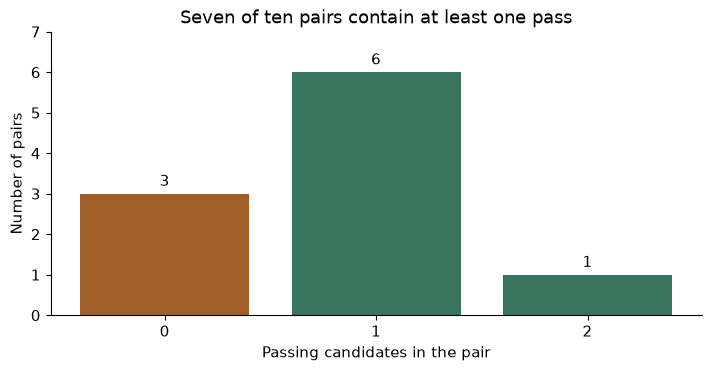

In [6]:
fig, ax = plt.subplots(layout="constrained")
counts = [len(groups[k]) for k in [0, 1, 2]]
bars = ax.bar([0, 1, 2], counts, color=["#a25e27", "#39745e", "#39745e"])
ax.bar_label(bars, padding=3)
ax.set(xticks=[0, 1, 2], xlabel="Passing candidates in the pair",
       ylabel="Number of pairs", ylim=(0, 7),
       title="Seven of ten pairs contain at least one pass")
display(fig)
plt.close(fig)

## 5. Inspect the evaluation record

Run the chapter's CLI and inspect `benchmark.candidates`. Candidate A, `touching_counts`, fails `touching` and `empty`. For touching intervals $[0,2)$ and $[2,5)$, $\ell=r=2$; it returns True although the expected answer is False. Candidate C, `needs_two`, fails `length_one`. For $[0,3)$ and $[2,4)$, the only common integer is 2, so the expected answer is True, but $r-\ell=1$ does not satisfy $r-\ell\ge2$.

The `edges` records contain the four additional cases, while `smoke` contains the original two. Combine them for six cases per candidate. Their passing counts are $4,6,5,6$, totaling $21/24=87.5\%$ of checks. Only B and D pass all six, giving $2/4=50\%$ of candidates. The two denominators answer different questions. The plot marks each individual result so a large average cannot hide a boundary failure.

In [7]:
import json, subprocess
from tempfile import TemporaryDirectory
with TemporaryDirectory() as temporary:
    output = Path(temporary) / "ch27.json"
    subprocess.run([sys.executable, "-m", "examples.ch27_code_models.run_examples",
                    "--output", str(output)], cwd=root, check=True, capture_output=True)
    report = json.loads(output.read_text())["benchmark"]
rows = report["candidates"]
case_results = [row["smoke"]["per_case"] + row["edges"]["per_case"] for row in rows]
matrix = [[record["passed"] for record in records] for records in case_results]
counts = [sum(row) for row in matrix]
assert counts == [4, 6, 5, 6]
assert sum(counts) == 21 and sum(all(row) for row in matrix) == 2
for label, row in zip("ABCD", rows):
    failed = [x["case"] for x in row["edges"]["per_case"] if not x["passed"]]
    print(f"{label} {row['name']}: {row['complete_passed_cases']}/6, failures={failed}")
print("Passing checks:", Fraction(sum(counts), 24))
print("Complete candidates:", Fraction(sum(all(row) for row in matrix), 4))

A touching_counts: 4/6, failures=['touching', 'empty']
B strict_overlap: 6/6, failures=[]
C needs_two: 5/6, failures=['length_one']
D positive_length: 6/6, failures=[]
Passing checks: 7/8
Complete candidates: 1/2


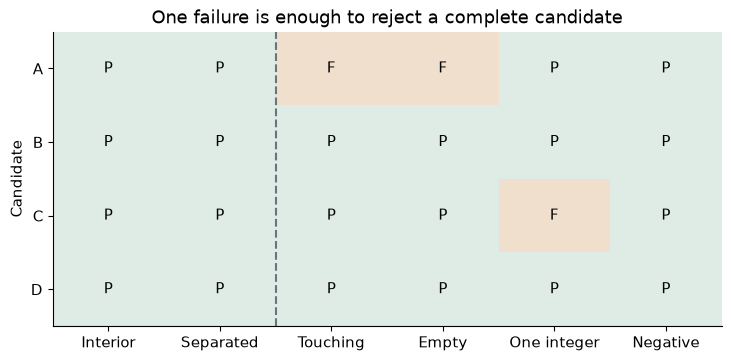

In [8]:
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(7.2, 3.5), layout="constrained")
ax.imshow(matrix, cmap=ListedColormap(["#f1dfcd", "#deece5"]), vmin=0, vmax=1, aspect="auto")
for i, row in enumerate(matrix):
    for j, passed in enumerate(row):
        ax.text(j, i, "P" if passed else "F", ha="center", va="center")
ax.set(xticks=range(6), xticklabels=["Interior", "Separated", "Touching", "Empty", "One integer", "Negative"],
       yticks=range(4), yticklabels=list("ABCD"), ylabel="Candidate",
       title="One failure is enough to reject a complete candidate")
ax.axvline(1.5, color="#687580", linestyle="--")
display(fig)
plt.close(fig)

## 6. Add one boundary case

Choose $[-5,-2)$ and $[-3,0)$. The first contains $-5,-4,-3$ and the second $-3,-2,-1$. Their only common integer is $-3$, so the expected result is True. Both starts are negative, and $\ell=-3$, $r=-2$, giving $r-\ell=1$.

The strict and positive-length functions return True, as does the non-strict function on this particular input. Only `needs_two` returns False. Passing this case does not repair the non-strict function: its equality error still appears on touching or empty intervals. We compute the expected result independently with set intersection before invoking the candidates.

In [9]:
case = Case("negative_start_length_one", (-5, -2), (-3, 0), True)
shared = set(range(*case.a)) & set(range(*case.b))
assert shared == {-3} and case.expected is bool(shared)
outcomes = []
for candidate in CANDIDATES:
    record = score_candidate(candidate, [case])["per_case"][0]
    outcomes.append(record["passed"])
    print(f"{candidate.__name__}: observed={record['observed']}, passed={record['passed']}")
assert outcomes == [True, True, False, True]

touching_counts: observed=True, passed=True
strict_overlap: observed=True, passed=True
needs_two: observed=False, passed=False
positive_length: observed=True, passed=True


## 7. Check the metric

For five candidates with two passes, $k=1$ gives $2/5=0.4$: two of five single-candidate subsets succeed. At $k=2$, seven of ten pairs succeed, giving $0.7$. At $k=5$, the only subset contains every candidate, including both passes, so the result is one. Each statement concerns a uniformly selected subset of the stated fixed pool.

The enumeration below checks the combinatorial helper independently. Choosing all candidates guarantees coverage only when at least one candidate passes; it does not supply a rule for identifying that candidate.

In [10]:
for k in (1, 2, 5):
    subsets = list(combinations("ABCDE", k))
    successes = sum(bool(set(group) & {"A", "B"}) for group in subsets)
    exact = Fraction(successes, len(subsets))
    assert pass_at_k(5, 2, k) == float(exact)
    print(f"k={k}: {exact} = {float(exact):.2f}")

k=1: 2/5 = 0.40
k=2: 7/10 = 0.70
k=5: 1 = 1.00


For the two-task extension, task one has $n=4,c=2$ and task two has $n=4,c=0$. Their $\mathrm{pass@}2$ values are $5/6$ and zero. The task average is $5/12\approx0.4167$. Treating all eight candidates as one pool gives $1-\binom{6}{2}/\binom{8}{2}=13/28\approx0.4643$. That pool includes pairs from different tasks, which cannot answer the question about two attempts at one task. The plot labels the pooled result as invalid for this benchmark aggregation.

In [11]:
task_scores = [pass_at_k(4, 2, 2), pass_at_k(4, 0, 2)]
task_mean = sum(task_scores) / len(task_scores)
invalid_pooled = pass_at_k(8, 2, 2)
assert task_mean == float(Fraction(5, 12))
assert invalid_pooled == float(Fraction(13, 28))
print("Per-task values:", task_scores)
print(f"Correct task average: {task_mean:.6f}")
print(f"Invalid pooled calculation: {invalid_pooled:.6f}")

Per-task values: [0.8333333333333334, 0.0]
Correct task average: 0.416667
Invalid pooled calculation: 0.464286


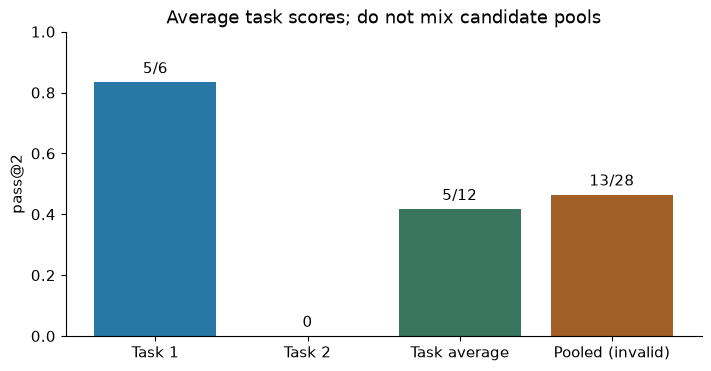

In [12]:
fig, ax = plt.subplots(layout="constrained")
values = [*task_scores, task_mean, invalid_pooled]
bars = ax.bar(range(4), values, color=["#2878a5", "#2878a5", "#39745e", "#a25e27"])
ax.bar_label(bars, labels=["5/6", "0", "5/12", "13/28"], padding=4)
ax.set(xticks=range(4), xticklabels=["Task 1", "Task 2", "Task average", "Pooled (invalid)"],
       ylim=(0, 1), ylabel="pass@2",
       title="Average task scores; do not mix candidate pools")
display(fig)
plt.close(fig)

A further check explains the distinction between a fixed pool and fresh draws. If a fresh attempt succeeds with true probability $p=1/2$, two independent attempts succeed with probability $1-(1-p)^2=3/4$. A pool with $n=4,c=2$ has subset coverage $5/6$, so this one pool overestimates that fresh-draw probability. Across repeatedly sampled pools, the possible counts $c=0,1,2,3,4$ have probabilities $(1,4,6,4,1)/16$. Weighting their subset estimates by those probabilities gives exactly $3/4$. This is what unbiasedness means; it does not make every observed estimate equal to the unknown truth.

In [13]:
expected_estimate = Fraction(0)
for correct in range(5):
    probability = Fraction(comb(4, correct), 16)
    coverage = 1 - Fraction(comb(4-correct, 2), comb(4, 2))
    expected_estimate += probability * coverage
assert expected_estimate == Fraction(3, 4)
print("Expected subset estimate under independent p=1/2:", expected_estimate)
print("One observed pool with c=2:", Fraction(5, 6))

Expected subset estimate under independent p=1/2: 3/4
One observed pool with c=2: 5/6


## 8. Separate selection from coverage

Call the 12-line, 18-line, and 7-line candidates A, B, and C. A and B pass. The shortest-candidate rule selects C, which fails, giving score zero on this task. Yet every size-two pair AB, AC, and BC contains a pass, so the pool has $\mathrm{pass@}2=1$.

The user receives the selected candidate, so the selector's pass rate across tasks describes the actual output. Pool coverage asks whether a good answer is available among several candidates. It does not measure whether the selection rule finds that answer. A test-based selector would additionally need tests available at selection time, separate from a final hidden evaluation suite.

In [14]:
candidates = [("A", 12, True), ("B", 18, True), ("C", 7, False)]
selected = min(candidates, key=lambda item: item[1])
selection_score = int(selected[2])
coverage = pass_at_k(3, sum(item[2] for item in candidates), 2)
assert selected[0] == "C" and selection_score == 0 and coverage == 1
print(f"Selected {selected[0]} ({selected[1]} lines): score={selection_score}")
print(f"Pool pass@2={coverage}")

Selected C (7 lines): score=0
Pool pass@2=1.0


## 9. Design a repository-context comparison

Consider a scheduling repository with `can_book` in `booking.py` and `occupied_span` in `time_slots.py`. The helper extends the end of every nonempty booking by ten minutes for cleanup, while an empty interval remains empty. The issue asks the availability checker to use this shared policy consistently on both the existing booking and the request.

In the local-only condition, provide the function and issue. In the retrieved-context condition, also provide the helper definition, its documentation, and relevant callers from the same base revision. Record what the retriever actually returned, not just the intended query. Keep model, decoding settings, maximum attempts, token budget, selection rule, and execution environment fixed. Reserve input capacity for retrieved passages in both conditions; record actual usage. Pair random draws where the experiment permits, and evaluate both sets of patches on the same held-out cases.

For an existing booking $[0,30)$, the occupied span is $[0,40)$. A request $[35,45)$ is rejected; $[40,50)$ and $[50,60)$ are accepted. An empty existing booking $[25,25)$ must not acquire cleanup time, so request $[26,30)$ is accepted. Also test cleanup on the request side: request $[15,25)$ occupies $[15,35)$ and conflicts with existing booking $[30,40)$. These cases distinguish the helper's policy from ordinary overlap and from a one-sided cleanup implementation.

The code below checks the proposed test expectations with a deliberately small reference helper. It is not a measured comparison of model-generated patches. Such a comparison should report per-case outcomes and complete-task pass fractions, including ordinary cases that detect regressions.

In [15]:
def occupied_span(interval, cleanup=10):
    start, end = interval
    return interval if start == end else (start, end + cleanup)

def reference_can_book(existing, request):
    return not strict_overlap(occupied_span(existing), occupied_span(request))

evaluation_cases = [
    ((0, 30), (35, 45), False),
    ((0, 30), (40, 50), True),
    ((0, 30), (50, 60), True),
    ((25, 25), (26, 30), True),
    ((30, 40), (15, 25), False),
]
for existing, request, expected in evaluation_cases:
    actual = reference_can_book(existing, request)
    assert actual is expected
    print(f"existing={existing}, request={request}: can_book={actual}")

existing=(0, 30), request=(35, 45): can_book=False
existing=(0, 30), request=(40, 50): can_book=True
existing=(0, 30), request=(50, 60): can_book=True
existing=(25, 25), request=(26, 30): can_book=True
existing=(30, 40), request=(15, 25): can_book=False


## 10. Check for regressions

Use the half-open contract from the issue, without the separate cleanup policy introduced in Exercise 9. The adjacent pair $[0,2)$ and $[2,4)$ must return False: the buggy non-strict comparison returns True, so this test must change from failing to passing. A genuine overlap $[0,3)$ and $[2,4)$ must remain True. A separated pair $[0,2)$ and $[3,4)$ must remain False. The last two are regression checks: they already passed before the fix.

An always-False patch passes the adjacent case but fails the overlap regression. A strict comparison passes all three. Thus repairing the reported symptom is not enough to resolve the complete tested task.

Give the model the issue report, current function, and stated contract. A public reproducer can be visible during repair; reserve additional boundary cases and the designated final regression suite for evaluation. Keep their expected outcomes fixed before testing. Record which tests the system could inspect or run while editing, rather than presenting feedback-driven repair as independent sampling.

In [16]:
checks = [
    Case("adjacent", (0, 2), (2, 4), False),
    Case("genuine_overlap", (0, 3), (2, 4), True),
    Case("separated", (0, 2), (3, 4), False),
]
def always_false(a, b):
    return False

for name, function, expected in [
    ("buggy", CANDIDATES[0], [False, True, True]),
    ("always_false", always_false, [True, False, True]),
    ("strict_fix", strict_overlap, [True, True, True]),
]:
    result = score_candidate(function, checks)
    outcomes = [item["passed"] for item in result["per_case"]]
    assert outcomes == expected
    print(f"{name}: outcomes={outcomes}, complete={result['passed_all']}")

buggy: outcomes=[False, True, True], complete=False
always_false: outcomes=[True, False, True], complete=False
strict_fix: outcomes=[True, True, True], complete=True


## 11. Audit a benchmark split

First group repository families, including forks, renamed mirrors, and copied projects. Record each task's issue date, base revision, patch date, and test provenance. Detect exact duplicates with hashes, then compare normalized issue text, edited functions, tests, and patch structure for near-duplicates. Renaming variables can hide a text match without changing the underlying repair. Review candidates for the same bug and fix; group duplicate clusters before splitting or discard cross-partition duplicates under a documented rule.

One possible design uses early tasks from family A for training, later tasks from family B for validation, and the latest window from family C for testing. Freeze both family assignments and date boundaries. A later task from an A fork must not enter the C test partition just because its date is recent. Report discarded tasks and the resulting number of repositories, tasks, and date ranges. The code illustrates these two simultaneous conditions; its dates and task IDs are synthetic.

For each evaluation task, expose only the base-revision snapshot and issue information available at the defined prediction time. Build retrieval from that snapshot. Exclude reference patches, later comments containing fixes, future helper implementations, hidden tests, and repository history that reveals the answer. Apply the candidate patch to the base revision and run the held-out tests separately. Check supplied context for leaked patch lines and test fixtures.

These controls address overlap within the benchmark and supplied context. Public issues or code could still have appeared in unknown pretraining data. Record model version, known training cutoff, and available exposure evidence. Report confirmed overlap, suspected overlap, and unknown cases separately. A date cutoff or a failed duplicate search alone does not prove absence of contamination.

In [17]:
from datetime import date
tasks = [
    {"id": "A-early", "family": "A", "date": "2024-02-01"},
    {"id": "B-later", "family": "B", "date": "2024-10-01"},
    {"id": "C-recent", "family": "C", "date": "2025-04-01"},
    {"id": "A-fork-recent", "family": "A", "date": "2025-05-01"},
]
rules = {
    "train": ("A", date(2024, 1, 1), date(2024, 7, 1)),
    "validation": ("B", date(2024, 7, 1), date(2025, 1, 1)),
    "test": ("C", date(2025, 1, 1), date(2025, 7, 1)),
}
assigned = {}
for task in tasks:
    when = date.fromisoformat(task["date"])
    matches = [name for name, (family, start, end) in rules.items()
               if task["family"] == family and start <= when < end]
    assert len(matches) <= 1
    assigned[task["id"]] = matches[0] if matches else "excluded"
assert assigned["A-fork-recent"] == "excluded"
for task, partition in assigned.items():
    print(task, "->", partition)

A-early -> train
B-later -> validation
C-recent -> test
A-fork-recent -> excluded


## Checks and next steps

All eleven solutions are covered, with three plots and executed assertions. The checks distinguish tested cases from complete candidates, fixed-pool coverage from fresh-draw probabilities, and available solutions from selected answers. The repository-context and split examples are evaluation designs with known synthetic expectations.

To extend the exercise, introduce a candidate that fails only on an empty interval or changes behavior after repeated calls. Add cases based on the contract, then report exactly which claim the larger suite supports. Passing more tests is useful evidence; it is not a proof about every possible input.